<p class="lead">Unit 11 showed that changing the representation moved the model's error far more than changing the algorithm. This unit is about the representation itself: how to build features from what you know about the chemistry or the biology, how to decide which of them to keep, and how to compress hundreds or thousands of columns into a handful you can look at. Three facts organise everything that follows. First, feature <em>construction</em> is where domain knowledge enters a model, and it is the step no library can do for you. Second, feature <em>selection</em> is a model fitted to the data and must therefore live inside the cross-validation, and even then its output is unstable when there are more columns than rows. Third, dimensionality <em>reduction</em> is a lossy compression whose losses you must be able to name: PCA preserves variance and distorts nothing linear, while t-SNE and UMAP preserve neighbourhoods and will happily draw clusters in data that have none. We work on two feature families with completely different statistics — 45 molecular descriptors and 2,048 fingerprint bits — plus a 500-gene expression slice where the columns outnumber the rows almost four to one.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad trata de la representación de los datos. Se construyen variables a partir del conocimiento del dominio (razones, transformaciones logarítmicas, interacciones, variables categóricas de alta cardinalidad mediante <em>hashing</em>); se comparan los tres tipos de selección de variables (filtro, envolvente y embebida) ejecutados siempre dentro de la validación cruzada, midiendo su estabilidad con el índice de Jaccard entre pliegues; se deriva el análisis de componentes principales a partir de la descomposición en valores singulares, con gráfico de sedimentación, cargas, biplot y error de reconstrucción; se comparan t-SNE y UMAP advirtiendo sobre los conglomerados falsos; y se demuestra por simulación la maldición de la dimensionalidad. Se usan descriptores y huellas moleculares de ROCK1 y un subconjunto de 500 genes de un estudio de periodontitis.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Engineer features from domain knowledge — descriptors, ratios, transformations, aggregates, high-cardinality encodings — and encode them without leakage.</li>
<li>Apply filter, wrapper and embedded selection (variance, correlation, mutual information, RFE, L1, permutation importance) inside cross-validation, and report selection stability with the Jaccard index.</li>
<li>Explain why selection rarely improves a regularised model's accuracy and what it is actually for.</li>
<li>Derive PCA from the singular value decomposition and read a scree plot, a loadings matrix, a biplot and a reconstruction error curve.</li>
<li>Use t-SNE and UMAP for visualisation, state what each preserves, and recognise a false cluster.</li>
<li>Explain the curse of dimensionality and demonstrate distance concentration by simulation.</li>
<li>Describe how fingerprints (sparse, binary, 2,048-dimensional), descriptors (dense, correlated, ~45-dimensional) and expression matrices (p ≫ n) differ statistically and what each demands of a method.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read linearly and run each cell. In Google Colab run <code>!pip install rdkit umap-learn</code> once before the setup cell; everything else is pre-installed. UMAP is optional — the setup cell imports it inside a <code>try</code> block and the notebook falls back to t-SNE alone with a printed message if it is unavailable. Unit 11 (pipelines and leakage) and Unit 12 (splits and validation) are prerequisites: every comparison here runs inside the cross-validation schemes those units established.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit umap-learn
from pathlib import Path
import os, tempfile, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, rdkit
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Descriptors
RDLogger.DisableLog("rdApp.*")
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
os.environ.setdefault("NUMBA_CACHE_DIR", tempfile.mkdtemp())   # some sandboxes cannot write numba's default cache
try:
    import umap
    HAVE_UMAP = True
except Exception as exc:
    HAVE_UMAP = False
    print("umap-learn unavailable (%s); the notebook will use t-SNE only." % type(exc).__name__)

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| rdkit", rdkit.__version__, "| umap:", HAVE_UMAP)

numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | rdkit 2026.03.4 | umap: True


In [2]:
# Three feature families: 45 RDKit descriptors, 2048 fingerprint bits, 500 genes. (~15 s)
df = load_data("rock1_chembl_curated.csv")
reg = df.loc[~df["censored"]].reset_index(drop=True)
y = reg["pActivity"].to_numpy()
scaffold = reg["scaffold_smiles"].to_numpy()
mols = [Chem.MolFromSmiles(s) for s in reg["std_smiles"]]
DESC_NAMES = ["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors", "NumRotatableBonds", "RingCount",
              "NumAromaticRings", "HeavyAtomCount", "FractionCSP3", "qed", "BalabanJ", "BertzCT", "Chi0n",
              "Chi1n", "Chi2n", "Chi3n", "Chi4n", "HallKierAlpha", "Kappa1", "Kappa2", "Kappa3", "LabuteASA",
              "MolMR", "NumAliphaticRings", "NumSaturatedRings", "NumHeteroatoms", "NHOHCount", "NOCount",
              "PEOE_VSA1", "PEOE_VSA6", "SMR_VSA5", "SlogP_VSA2", "SlogP_VSA5", "EState_VSA3", "EState_VSA5",
              "MaxPartialCharge", "MinPartialCharge", "NumValenceElectrons", "HeavyAtomMolWt", "ExactMolWt",
              "NumAromaticHeterocycles", "NumSaturatedHeterocycles", "MaxEStateIndex", "MinEStateIndex"]
_f = dict(Descriptors._descList)
D = np.array([[_f[n](m) for n in DESC_NAMES] for m in mols])
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
FP = np.array([gen.GetFingerprintAsNumPy(m) for m in mols], dtype=np.float32)
fps = [gen.GetFingerprint(m) for m in mols]
expr = load_data("geo_periodontitis_expr.csv", index_col=0)
meta = load_data("geo_periodontitis_meta.csv").set_index("sample_id")
top500 = expr.var(axis=1).sort_values(ascending=False).head(500).index
E = expr.loc[top500].T.to_numpy()
E_label = (meta.loc[expr.columns, "status"] == "diseased").astype(int).to_numpy()
print("descriptors   %5d x %4d  (dense, continuous)" % D.shape)
print("fingerprints  %5d x %4d  (sparse binary, %.1f%% of entries are 1)" % (*FP.shape, 100 * FP.mean()))
print("expression    %5d x %4d  (p >> n: %d samples, %d genes)" % (*E.shape, *E.shape))
print("missing values: descriptors %d | expression %d" % (int(np.isnan(D).sum()), int(np.isnan(E).sum())))

descriptors    2764 x   45  (dense, continuous)
fingerprints   2764 x 2048  (sparse binary, 2.6% of entries are 1)
expression      138 x  500  (p >> n: 138 samples, 500 genes)
missing values: descriptors 0 | expression 0


## 1. A feature matrix is a scientific claim

Choosing features is choosing what the model is allowed to notice. A molecular weight column asserts that size matters; a fingerprint bit asserts that the presence of one particular substructure matters; a gene column asserts that the expression of that gene matters. The three families loaded above differ not only in size but in their whole statistical character, and almost every practical difficulty in this unit follows from those differences.

<div class="box bridge"><h4>Domain context — descriptors, fingerprints and expression matrices</h4>
<p>A <strong>molecular descriptor</strong> is a number computed from a structure that means something physical: molecular weight, the calculated oil/water partition coefficient logP (greasiness), the topological polar surface area TPSA (how much polar surface the molecule exposes), counts of rings and rotatable bonds, graph-theoretical indices such as Balaban's J or the Bertz complexity, and surface-area descriptors binned by partial charge (the <code>PEOE_VSA</code>, <code>SlogP_VSA</code> and <code>EState_VSA</code> families)<sup class="c"><a href="#r28">[28]</a></sup>. Descriptors are dense, continuous and heavily correlated, because most of them are partly measures of size. A <strong>fingerprint</strong> is a long binary vector in which bit <em>i</em> records whether a particular circular substructure is present<sup class="c"><a href="#r27">[27]</a></sup>; it is sparse (about 2.5% of bits set here), each column is almost meaningless alone, and the useful information is in combinations. A <strong>gene-expression matrix</strong> from a microarray or RNA-seq experiment has one column per gene (tens of thousands) and one row per sample (tens to hundreds): the <em>p ≫ n</em> regime, where almost any pattern can be fitted and nothing can be trusted without stability analysis. Our expression slice comes from gingival tissue of patients with periodontitis — a chronic inflammatory disease of the tooth-supporting tissues — in which each patient contributed one diseased and one healthy site<sup class="c"><a href="#r30">[30]</a></sup><sup class="c"><a href="#r31">[31]</a></sup>.</p></div>

In [3]:
# The statistical signature of each family: spread, correlation and sparsity.
from scipy.stats import skew
def pair_corr(M, max_cols=400, seed=0):
    '''Median absolute pairwise correlation over a random sample of non-constant columns.'''
    keep = np.where(M.std(axis=0) > 0)[0]                      # constant columns have no correlation
    cols = np.random.RandomState(seed).choice(keep, min(max_cols, len(keep)), replace=False)
    C = np.corrcoef(M[:, cols], rowvar=False)
    return np.abs(C[np.triu_indices(len(cols), 1)])
stats_tbl = pd.DataFrame({
    "family": ["descriptors (45)", "fingerprints (2048)", "expression (500 genes)"],
    "rows": [D.shape[0], FP.shape[0], E.shape[0]],
    "columns": [D.shape[1], FP.shape[1], E.shape[1]],
    "rows_per_column": [D.shape[0] / D.shape[1], FP.shape[0] / FP.shape[1], E.shape[0] / E.shape[1]],
    "fraction_nonzero": [1.0, float(FP.mean()), 1.0],
    "median_|corr|": [np.median(pair_corr(D)), np.median(pair_corr(FP)), np.median(pair_corr(E))],
    "max_|skew|": [np.nanmax(np.abs(skew(D, axis=0))), np.nanmax(np.abs(skew(FP, axis=0))),  # constant bits give NaN
                   np.nanmax(np.abs(skew(E, axis=0)))],
}).set_index("family")
stats_tbl.round(3)

<cell 3>:16: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.


,rows,columns,rows_per_column,fraction_nonzero,median_|corr|,max_|skew|
family,,,,,,
descriptors (45),2764,45,61.422,1.000,0.375,2.883
fingerprints (2048),2764,2048,1.350,0.026,0.007,52.548
expression (500 genes),138,500,0.276,1.000,0.295,4.696


<p class="caption"><b>Table (Section 1).</b> The three families compared. Descriptors have 61 rows per column — comfortable for any method — a median absolute pairwise correlation of about 0.38, which is very high (most of them partly measure size), and a worst skewness near 2.9 (<code>NHOHCount</code>, a count bounded below by zero). Fingerprints have only about 1.3 rows per column, 2.6% of their entries set, and a median pairwise correlation near zero over the non-constant bits, because most bit pairs never co-occur. The expression slice has 0.28 rows per column: fewer samples than genes, the regime in which a linear model can fit the training data exactly and learn nothing. Every method in this unit behaves differently on these three matrices, and the rows-per-column ratio is the best single predictor of how much trouble you are in.</p>

## 2. Constructing features from domain knowledge

### 2.1 Ratios, densities and transformations

Medicinal chemistry has a vocabulary of *derived* quantities that are more informative than their parts: polar surface per unit mass, lipophilicity per heavy atom (the basis of ligand-efficiency metrics), the ratio of aromatic to total rings, flexibility per atom. These are exactly the interaction and ratio features a model with limited capacity cannot invent for itself, because a linear model can add columns but cannot divide them.

In [4]:
# Six engineered features from chemical intuition, and whether they earn their place.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_validate, cross_val_score, GroupKFold
cv5 = KFold(5, shuffle=True, random_state=0)
d = pd.DataFrame(D, columns=DESC_NAMES)
eng = pd.DataFrame({
    "polar_density": d["TPSA"] / d["MolWt"],                      # polar surface per unit mass
    "logp_per_heavy": d["MolLogP"] / d["HeavyAtomCount"],         # lipophilic efficiency per atom
    "hbd_hba_ratio": (d["NumHDonors"] + 1) / (d["NumHAcceptors"] + 1),
    "aromatic_fraction": d["NumAromaticRings"] / d["RingCount"].clip(lower=1),
    "flexibility": d["NumRotatableBonds"] / d["HeavyAtomCount"].clip(lower=1),
    "log_MolWt": np.log(d["MolWt"])}).to_numpy()
X11 = d[["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors", "NumRotatableBonds",
         "NumAromaticRings", "RingCount", "HeavyAtomCount", "FractionCSP3", "qed"]].to_numpy()
rows = []
for name, M in [("11 basic descriptors", X11), ("11 basic + 6 engineered", np.hstack([X11, eng])),
                ("45-descriptor panel", D)]:
    r_ridge = cross_val_score(Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=10.0))]), M, y, cv=cv5, scoring="r2")
    r_rf = cross_val_score(RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1), M, y, cv=cv5, scoring="r2")
    rows.append({"features": name, "p": M.shape[1], "ridge_R2": r_ridge.mean(), "forest_R2": r_rf.mean()})
pd.DataFrame(rows).set_index("features").round(3)

,p,ridge_R2,forest_R2
features,,,
11 basic descriptors,11,0.112,0.324
11 basic + 6 engineered,17,0.120,0.325
45-descriptor panel,45,0.194,0.445


<p class="caption"><b>Table (Section 2.1).</b> Six hand-built ratio features added to eleven basic descriptors raise the ridge R² from about 0.11 to 0.12 and leave the random forest unchanged at about 0.32 — essentially nothing. Moving instead from 11 to the 45-descriptor panel lifts ridge to about 0.19 and the forest to about 0.44. The lesson is uncomfortable and worth absorbing: a tree ensemble can already construct ratios and interactions implicitly by splitting on both parents, so hand-crafted ratios buy little for it, while for a linear model they help only when the ratio really is the mechanism. Feature engineering pays when it <em>adds information</em> (more descriptors, a new assay, a structural feature) and rarely when it only rearranges information the model already has.</p>

### 2.2 Transformations: making a column usable

Skewed, heavy-tailed or zero-inflated columns violate the implicit assumptions of distance-based and linear methods. The classical remedies are the logarithm, the Box–Cox family<sup class="c"><a href="#r33">[33]</a></sup> and its zero-tolerant Yeo–Johnson variant, binning, and — for the surface-area descriptors that are zero for most molecules — an indicator column plus the value.

most skewed columns: {'NHOHCount': 2.9, 'NumHDonors': 2.4, 'MinEStateIndex': 2.0, 'TPSA': 2.0, 'Chi4n': 1.9}
ridge R2: raw+standardise 0.194 | Yeo-Johnson 0.197 | quantile-normal 0.189


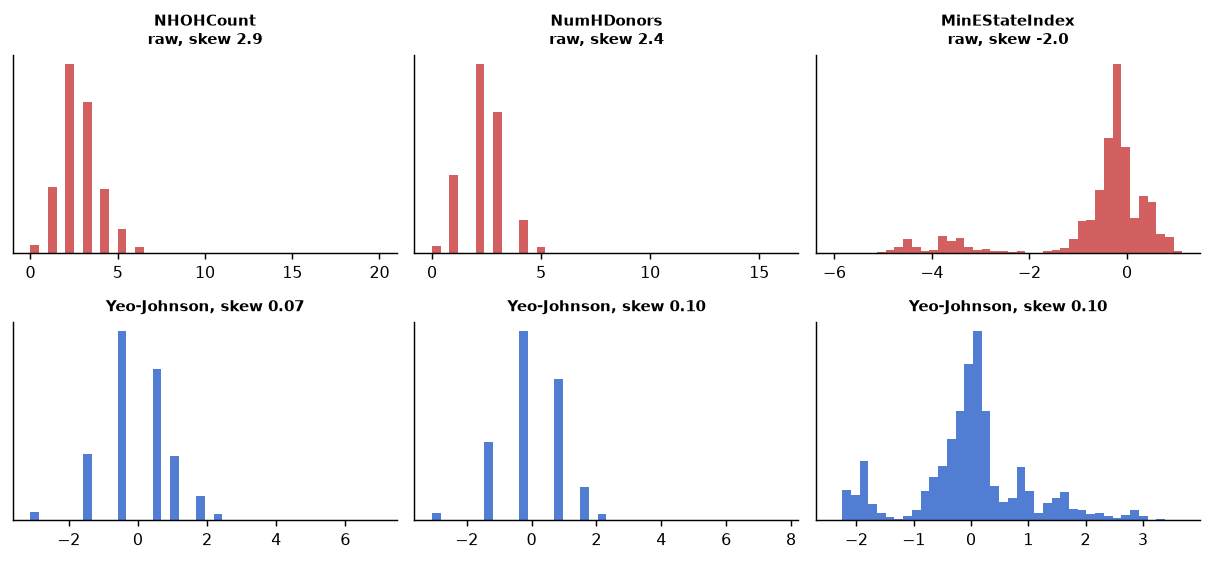

In [5]:
# Before and after: the three most skewed descriptor columns under a Yeo-Johnson power transform.
from sklearn.preprocessing import PowerTransformer, QuantileTransformer
sk = pd.Series(skew(D, axis=0), index=DESC_NAMES).abs().sort_values(ascending=False)
worst = list(sk.index[:3])
yj = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(D)
fig, axes = plt.subplots(2, 3, figsize=(9.4, 4.4))
for j, name in enumerate(worst):
    c = DESC_NAMES.index(name)
    axes[0, j].hist(D[:, c], bins=40, color="#c44", alpha=0.85)
    axes[0, j].set_title(f"{name}\nraw, skew {skew(D[:, c]):.1f}", fontsize=8.5)
    axes[1, j].hist(yj[:, c], bins=40, color="#36c", alpha=0.85)
    axes[1, j].set_title(f"Yeo-Johnson, skew {skew(yj[:, c]):.2f}", fontsize=8.5)
for ax in axes.ravel():
    ax.set_yticks([])
fig.tight_layout()
print("most skewed columns:", {k: round(v, 1) for k, v in sk.head(5).items()})
r_raw = cross_val_score(Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=10.0))]), D, y, cv=cv5, scoring="r2").mean()
r_yj = cross_val_score(Pipeline([("pt", PowerTransformer()), ("m", Ridge(alpha=10.0))]), D, y, cv=cv5, scoring="r2").mean()
r_qt = cross_val_score(Pipeline([("qt", QuantileTransformer(output_distribution="normal", random_state=0)),
                                 ("m", Ridge(alpha=10.0))]), D, y, cv=cv5, scoring="r2").mean()
print("ridge R2: raw+standardise %.3f | Yeo-Johnson %.3f | quantile-normal %.3f" % (r_raw, r_yj, r_qt))

<p class="caption"><b>Figure 1.</b> The three most skewed descriptor columns before (red) and after (blue) a Yeo–Johnson power transform. Raw skewness of about 2–3 — hydrogen-bond-donor counts and polar surface area, both bounded below by zero with a long right tail — becomes essentially zero. The cross-validated effect on ridge regression, printed below the figure, is almost nil: R² moves from about 0.194 to about 0.197 with Yeo–Johnson and <em>down</em> to about 0.189 with a quantile transform. That is the honest result and it is worth keeping: symmetrising a predictor helps distance-based methods, visual inspection and coefficient interpretation, but a regularised linear model on 45 columns does not need it. Note that both transforms are <em>fitted</em> (they learn an exponent or a set of quantiles), so both belong inside the pipeline — a transform fitted on the full dataset is item one of Unit 11's leakage catalogue.</p>

### 2.3 High-cardinality categoricals and feature hashing

Some columns are categorical with hundreds or thousands of levels: the scaffold of a molecule (1,218 distinct values here), a target gene, an assay identifier, a hospital. One-hot encoding them adds a column per level, most of which are seen once. **Feature hashing** maps each level through a hash function into a fixed number of buckets<sup class="c"><a href="#r29">[29]</a></sup>, trading collisions for a bounded, fixed-width representation that needs no vocabulary and handles unseen levels gracefully.

In [6]:
# Scaffold identity as a hashed categorical feature: 1218 levels into 256 buckets.
from sklearn.feature_extraction import FeatureHasher
hasher = FeatureHasher(n_features=256, input_type="string")
H = hasher.transform([[s] for s in scaffold]).toarray()
X_desc_scaled = StandardScaler().fit_transform(X11)
X_hashed = np.hstack([X_desc_scaled, H])
r_plain = cross_val_score(Ridge(alpha=10.0), X_desc_scaled, y, cv=cv5, scoring="r2").mean()
r_hash = cross_val_score(Ridge(alpha=10.0), X_hashed, y, cv=cv5, scoring="r2").mean()
print("distinct scaffolds: %d  ->  one-hot would add %d columns; hashing adds 256" % (len(set(scaffold)), len(set(scaffold))))
buckets = np.array([np.flatnonzero(r)[0] for r in hasher.transform([[s] for s in sorted(set(scaffold))]).toarray()])
print("buckets actually used: %d of 256 | most crowded bucket holds %d scaffolds | colliding scaffolds: %d"
      % (len(set(buckets)), int(np.bincount(buckets).max()), len(set(scaffold)) - len(set(buckets))))
print("ridge R2 with 11 descriptors            : %.3f" % r_plain)
print("ridge R2 with 11 descriptors + hashed scaffold: %.3f" % r_hash)

distinct scaffolds: 1218  ->  one-hot would add 1218 columns; hashing adds 256
buckets actually used: 255 of 256 | most crowded bucket holds 13 scaffolds | colliding scaffolds: 963
ridge R2 with 11 descriptors            : 0.112
ridge R2 with 11 descriptors + hashed scaffold: 0.194


Adding the hashed scaffold lifts R² from about 0.11 to about 0.19 — apparently the best feature-engineering result of the unit so far. It is also a trap, and the next cell springs it.

### 2.4 A failure mode: a feature that only works under the wrong split

Scaffold identity tells the model which series a compound belongs to. Under a random split, most test compounds share their scaffold with training compounds, so the feature acts as a lookup table of series averages — genuinely predictive, and genuinely useless for the question "how potent is a compound from a series we have not worked on?". Under the scaffold split of Unit 12 the lookup table has no entry, and the 256 extra columns become pure noise for the regulariser to fight.

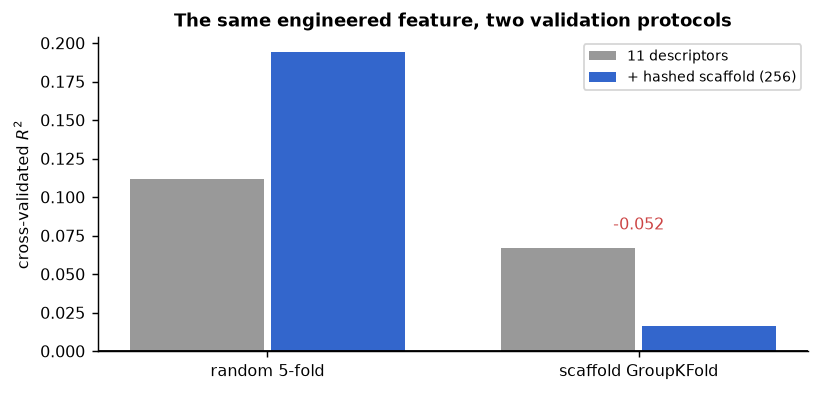

,descriptors_only,plus_hashed_scaffold,gain
protocol,,,
random 5-fold,0.112,0.194,0.082
scaffold GroupKFold,0.067,0.016,-0.052


In [7]:
# The same feature, judged by two splits.
rows = []
for name, cv, grp in [("random 5-fold", cv5, None), ("scaffold GroupKFold", GroupKFold(5), scaffold)]:
    a = cross_val_score(Ridge(alpha=10.0), X_desc_scaled, y, cv=cv, groups=grp, scoring="r2").mean()
    b = cross_val_score(Ridge(alpha=10.0), X_hashed, y, cv=cv, groups=grp, scoring="r2").mean()
    rows.append({"protocol": name, "descriptors_only": a, "plus_hashed_scaffold": b, "gain": b - a})
gain_tbl = pd.DataFrame(rows).set_index("protocol").round(3)
fig, ax = plt.subplots(figsize=(6.4, 3.1))
xp = np.arange(2)
ax.bar(xp - 0.19, gain_tbl["descriptors_only"], 0.36, label="11 descriptors", color="#999")
ax.bar(xp + 0.19, gain_tbl["plus_hashed_scaffold"], 0.36, label="+ hashed scaffold (256)", color="#36c")
for i, g in enumerate(gain_tbl["gain"]):
    ax.annotate(f"{g:+.3f}", (i, max(gain_tbl.iloc[i, 0], gain_tbl.iloc[i, 1]) + 0.012), ha="center", fontsize=9,
                color="#1a7" if g > 0 else "#c44")
ax.axhline(0, color="k", lw=1)
ax.set_xticks(xp); ax.set_xticklabels(gain_tbl.index); ax.set_ylabel("cross-validated $R^2$")
ax.set_title("The same engineered feature, two validation protocols"); ax.legend(fontsize=7.5)
fig.tight_layout()
gain_tbl

<p class="caption"><b>Figure 2 and table.</b> The hashed-scaffold feature adds about +0.08 R² under a random split and <em>subtracts</em> about 0.05 under a scaffold split, where it turns a weak model (R² ≈ 0.07) into a useless one (R² ≈ 0.02). Nothing changed except the question being asked. This is the most important practical lesson of the unit: <strong>every feature-engineering decision must be evaluated under the split that matches the deployment claim</strong>, because identity-like features (series, patient, batch, site, assay) are reliable predictors of the training set and silent on anything new. The clinical analogue is adding <code>patient_id</code> or <code>hospital</code> as a feature, which improves every random-split metric and predicts nothing about the next patient.</p>

<div class="exercise"><h4>Exercise 1</h4>
<p>Replace the hashed scaffold by a <em>target-encoded</em> scaffold: each compound's scaffold replaced by the mean pActivity of that scaffold, computed inside each training fold only. Measure it under both protocols. Then compute it once on the whole dataset (the wrong way) and measure again; report the three numbers and say which of the two errors — wrong encoding or wrong split — costs more.</p></div>

## 3. Feature selection

Selection methods come in three families, distinguished by how much they know about the model<sup class="c"><a href="#r1">[1]</a></sup><sup class="c"><a href="#r2">[2]</a></sup>.

- **Filters** score each feature independently of any model: variance, absolute correlation with the target, the univariate F statistic, mutual information (which detects non-linear dependence). Cheap, model-agnostic, and blind to redundancy — two perfectly correlated useful features both score highly and both get selected.
- **Wrappers** use the model itself: recursive feature elimination (RFE) fits, ranks, drops the weakest, and repeats<sup class="c"><a href="#r6">[6]</a></sup>. Expensive (one fit per elimination round), aware of interactions, and prone to overfitting the selection when data are scarce.
- **Embedded** methods select as part of fitting: the L1 penalty of the lasso drives coefficients exactly to zero<sup class="c"><a href="#r7">[7]</a></sup>, the elastic net does the same while keeping correlated groups together<sup class="c"><a href="#r8">[8]</a></sup>, and tree ensembles report impurity-based importances.

Whatever the family, the selection must be **refitted inside every training fold**: selecting on the whole dataset and then cross-validating is the leak that turns noise into apparent signal<sup class="c"><a href="#r3">[3]</a></sup> (Unit 11 measured it). In scikit-learn that means putting the selector in the `Pipeline`, exactly as below.

In [8]:
# Five selection strategies on the 45 descriptors, all refitted inside each fold.
from sklearn.feature_selection import (SelectKBest, f_regression, mutual_info_regression, RFE,
                                       SelectFromModel, VarianceThreshold)
from sklearn.linear_model import Lasso
def mi_scorer(Xa, ya):
    return mutual_info_regression(Xa, ya, random_state=0)
strategies = {
    "all 45 descriptors": Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=10.0))]),
    "variance filter (>0.01)": Pipeline([("sc", StandardScaler()), ("sel", VarianceThreshold(0.01)), ("m", Ridge(alpha=10.0))]),
    "top-20 |correlation|": Pipeline([("sc", StandardScaler()), ("sel", SelectKBest(f_regression, k=20)), ("m", Ridge(alpha=10.0))]),
    "top-20 mutual information": Pipeline([("sc", StandardScaler()), ("sel", SelectKBest(mi_scorer, k=20)), ("m", Ridge(alpha=10.0))]),
    "RFE to 20 (ridge)": Pipeline([("sc", StandardScaler()), ("sel", RFE(Ridge(alpha=10.0), n_features_to_select=20, step=2)), ("m", Ridge(alpha=10.0))]),
    "L1 (lasso) selected": Pipeline([("sc", StandardScaler()), ("sel", SelectFromModel(Lasso(alpha=0.02, max_iter=5000))), ("m", Ridge(alpha=10.0))]),
}
rows = []
for name, pipe in strategies.items():
    s = cross_validate(pipe, D, y, cv=cv5, scoring=["r2", "neg_root_mean_squared_error"])
    rows.append({"strategy": name, "R2": s["test_r2"].mean(), "R2_sd": s["test_r2"].std(),
                 "RMSE": -s["test_neg_root_mean_squared_error"].mean(), "fit_s": s["fit_time"].mean()})
sel_tbl = pd.DataFrame(rows).set_index("strategy").round(3)
sel_tbl

,R2,R2_sd,RMSE,fit_s
strategy,,,,
all 45 descriptors,0.194,0.039,0.992,0.002
variance filter (>0.01),0.194,0.039,0.992,0.002
top-20 |correlation|,0.118,0.046,1.038,0.002
top-20 mutual information,0.133,0.040,1.029,0.216
RFE to 20 (ridge),0.170,0.031,1.007,0.011
L1 (lasso) selected,0.160,0.041,1.013,0.003


<p class="caption"><b>Table (Section 3).</b> Six protocols, one model. Keeping all 45 descriptors gives the best cross-validated R² (about 0.19); every selection method <em>loses</em> accuracy — the correlation filter most (about 0.12), mutual information a little less (about 0.13), RFE and the lasso in between (about 0.17 and 0.16). The ranking is not an accident: ridge regression already handles redundant columns by shrinking them, so removing columns can only remove information. Selection is therefore not an accuracy tool here. It is a tool for <em>interpretability</em> (a model with 20 named descriptors can be discussed with a chemist), for <em>cost</em> (fewer descriptors to compute, fewer genes to assay in a clinical panel), and for <em>stability</em> of the scientific story. When a paper reports that selection improved performance, ask whether the selection was refitted inside the folds.</p>

In [9]:
# Which features does each method choose, and do they agree? (Jaccard stability across folds)
def selected_per_fold(make_selector):
    sets = []
    for tr, _ in cv5.split(D, y):
        Z = StandardScaler().fit_transform(D[tr])
        sel = make_selector().fit(Z, y[tr])
        sets.append(set(np.where(sel.get_support())[0]))
    return sets
def mean_jaccard(sets):
    return float(np.mean([len(a & b) / len(a | b) for i, a in enumerate(sets) for b in sets[i + 1:]]))
makers = {"top-20 |correlation|": lambda: SelectKBest(f_regression, k=20),
          "top-20 mutual information": lambda: SelectKBest(mi_scorer, k=20),
          "RFE to 20 (ridge)": lambda: RFE(Ridge(alpha=10.0), n_features_to_select=20, step=2),
          "L1 (lasso) selected": lambda: SelectFromModel(Lasso(alpha=0.02, max_iter=5000))}
stab = {}
for name, mk in makers.items():
    sets = selected_per_fold(mk)
    stab[name] = {"mean_Jaccard": mean_jaccard(sets), "sizes": [len(s) for s in sets],
                  "in_all_folds": len(set.intersection(*sets))}
    print("%-26s Jaccard %.3f | sizes %s | selected in all 5 folds: %d"
          % (name, stab[name]["mean_Jaccard"], stab[name]["sizes"], stab[name]["in_all_folds"]))
core = sorted(set.intersection(*selected_per_fold(lambda: SelectKBest(f_regression, k=20))))
print("\nthe 15 descriptors chosen by the correlation filter in every fold:")
print([DESC_NAMES[i] for i in core])

top-20 |correlation|       Jaccard 0.776 | sizes [20, 20, 20, 20, 20] | selected in all 5 folds: 15
top-20 mutual information  Jaccard 0.768 | sizes [20, 20, 20, 20, 20] | selected in all 5 folds: 15
RFE to 20 (ridge)          Jaccard 0.683 | sizes [20, 20, 20, 20, 20] | selected in all 5 folds: 12
L1 (lasso) selected        Jaccard 0.799 | sizes [18, 17, 16, 19, 18] | selected in all 5 folds: 14

the 15 descriptors chosen by the correlation filter in every fold:
['NumRotatableBonds', 'NumAromaticRings', 'FractionCSP3', 'Chi0n', 'Chi1n', 'Kappa1', 'Kappa2', 'Kappa3', 'PEOE_VSA1', 'SMR_VSA5', 'SlogP_VSA5', 'MinPartialCharge', 'NumValenceElectrons', 'NumAromaticHeterocycles', 'MaxEStateIndex']


With 2,764 rows and 45 columns the selections are reasonably stable: mean Jaccard between folds is about 0.78 for the correlation filter, 0.77 for mutual information, 0.68 for RFE and 0.80 for the lasso, and 12–15 of the 20 chosen descriptors are the same in all five folds. RFE is the least stable, as wrappers usually are, because a small change in the training set reverses a close elimination decision early and the error propagates. The printed core set — the Chi connectivity and Kappa shape indices, rotatable bonds, aromatic rings, the fraction of sp3 carbons, surface-area descriptors and the extreme partial charge and E-state values — is the part of the story a chemist can be told.

### 3.1 Permutation importance

Impurity-based importances from trees are biased towards high-cardinality and continuous features<sup class="c"><a href="#r10">[10]</a></sup>. **Permutation importance** avoids that by measuring the loss of performance when one column is shuffled<sup class="c"><a href="#r9">[9]</a></sup>, which is model-agnostic and directly interpretable — but must be computed on *held-out* data, otherwise it reports what the model memorised rather than what it uses.

                  impurity  permutation  perm_sd
MaxPartialCharge    0.0884       0.1474   0.0140
MaxEStateIndex      0.0816       0.1089   0.0123
MinPartialCharge    0.0941       0.0918   0.0057
HallKierAlpha       0.0498       0.0681   0.0120
BalabanJ            0.0432       0.0263   0.0016
SlogP_VSA5          0.0368       0.0248   0.0045
TPSA                0.0335       0.0215   0.0022
MinEStateIndex      0.0390       0.0179   0.0054

sum of impurity importances = 1.00 (always 1) | sum of permutation importances = 0.701


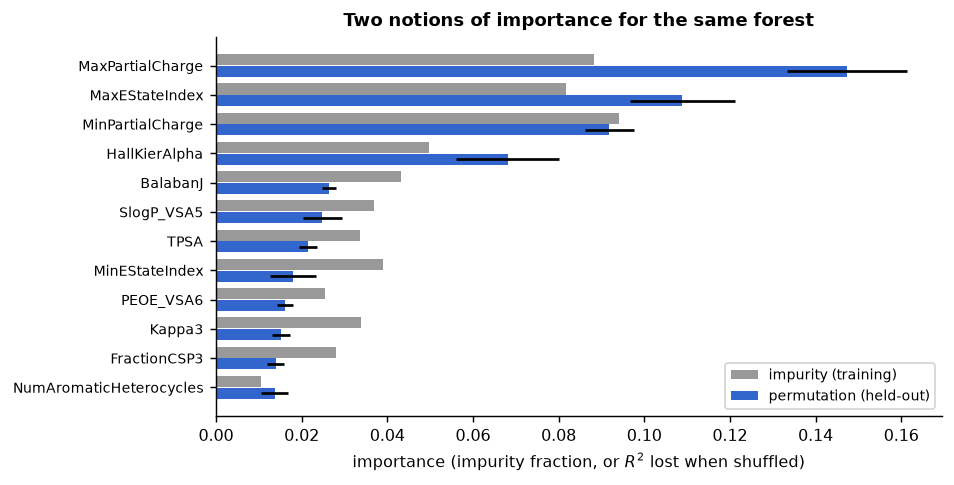

In [10]:
# Permutation importance on held-out data, next to the forest's impurity importance.
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
tr, te = train_test_split(np.arange(len(y)), test_size=0.25, random_state=0)
forest = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1).fit(D[tr], y[tr])
perm = permutation_importance(forest, D[te], y[te], n_repeats=5, random_state=0, scoring="r2")
imp = pd.DataFrame({"impurity": forest.feature_importances_, "permutation": perm.importances_mean,
                    "perm_sd": perm.importances_std}, index=DESC_NAMES).sort_values("permutation", ascending=False)
fig, ax = plt.subplots(figsize=(7.4, 3.8))
top = imp.head(12).iloc[::-1]
ax.barh(np.arange(len(top)) + 0.2, top["impurity"], 0.38, color="#999", label="impurity (training)")
ax.barh(np.arange(len(top)) - 0.2, top["permutation"], 0.38, xerr=top["perm_sd"], color="#36c",
        label="permutation (held-out)")
ax.set_yticks(np.arange(len(top))); ax.set_yticklabels(top.index, fontsize=8)
ax.set_xlabel("importance (impurity fraction, or $R^2$ lost when shuffled)")
ax.set_title("Two notions of importance for the same forest"); ax.legend(fontsize=7.5)
fig.tight_layout()
print(imp.head(8).round(4).to_string())
print("\nsum of impurity importances = %.2f (always 1) | sum of permutation importances = %.3f"
      % (imp['impurity'].sum(), imp['permutation'].sum()))

<p class="caption"><b>Figure 3.</b> The twelve most important descriptors by permutation importance (blue, measured on held-out compounds) with the forest's impurity importance for comparison (grey). The two rankings broadly agree at the top but not in detail, and their scales are different by construction: impurity importances are a decomposition of the training fit and sum to 1, while permutation importances are R² units lost on unseen data and sum to considerably more than the model's total R² because correlated descriptors share credit — shuffling one of two near-duplicate columns leaves the other to carry the signal, so both can look unimportant, or both important, depending on the correlation structure. With descriptor blocks as correlated as these, importances are a guide to the story, never a proof of mechanism; Unit 16 treats the problem properly.</p>

### 3.2 The p ≫ n regime: selection on gene expression

Everything above was comfortable because there were sixty rows per column. The expression slice has 138 samples and 500 genes. The same filter, the same code, a completely different outcome.

descriptors (2764 x 45): mean Jaccard 0.776
genes       (138 x 500): mean Jaccard 0.325 | selected in all 5 folds: 3 of 20
genes selected at least once: 44 | classification ROC-AUC with selection inside CV: 0.911 (folds [0.87 0.92 0.83 0.99 0.95])
top genes by selection frequency: ['MAP2', 'COL15A1', 'CHST2', 'FAM83C', 'YOD1', 'ICAM2']


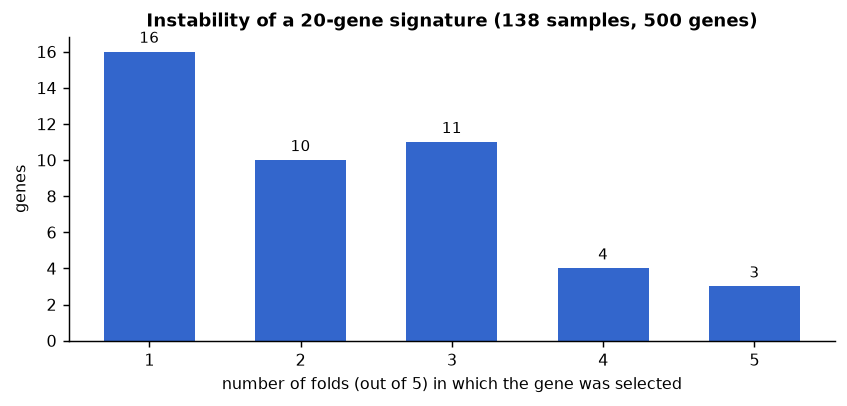

In [11]:
# The same selection protocol on 138 samples x 500 genes.
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
cv_gene = StratifiedKFold(5, shuffle=True, random_state=0)
gene_sets = []
for tr_g, _ in cv_gene.split(E, E_label):
    s = SelectKBest(f_classif, k=20).fit(StandardScaler().fit_transform(E[tr_g]), E_label[tr_g])
    gene_sets.append(set(np.where(s.get_support())[0]))
auc = cross_val_score(Pipeline([("sc", StandardScaler()), ("sel", SelectKBest(f_classif, k=20)),
                                ("m", LogisticRegression(max_iter=2000))]), E, E_label, cv=cv_gene, scoring="roc_auc")
freq = pd.Series(0, index=range(E.shape[1]))
for s in gene_sets:
    for i in s:
        freq[i] += 1
fig, ax = plt.subplots(figsize=(6.6, 3.2))
counts = freq[freq > 0].value_counts().sort_index()
ax.bar(counts.index, counts.values, color="#36c", width=0.6)
ax.set_xlabel("number of folds (out of 5) in which the gene was selected"); ax.set_ylabel("genes")
ax.set_title("Instability of a 20-gene signature (138 samples, 500 genes)")
for xx, vv in counts.items():
    ax.text(xx, vv + 0.5, str(int(vv)), ha="center", fontsize=8.5)
fig.tight_layout()
print("descriptors (2764 x 45): mean Jaccard %.3f" % stab["top-20 |correlation|"]["mean_Jaccard"])
print("genes       (138 x 500): mean Jaccard %.3f | selected in all 5 folds: %d of 20"
      % (mean_jaccard(gene_sets), len(set.intersection(*gene_sets))))
print("genes selected at least once: %d | classification ROC-AUC with selection inside CV: %.3f (folds %s)"
      % (int((freq > 0).sum()), auc.mean(), np.round(auc, 2)))
print("top genes by selection frequency:", [top500[i] for i in freq.sort_values(ascending=False).head(6).index])

<p class="caption"><b>Figure 4.</b> How often each gene enters the 20-gene signature across five folds. Only three genes are selected in all five folds, while dozens appear once or twice: the mean Jaccard overlap between folds is about 0.33, against about 0.78 for the molecular descriptors. The classifier nevertheless achieves a cross-validated ROC-AUC near 0.91, which is the paradox of <em>p ≫ n</em> data — the <strong>signature is unstable but the prediction is good</strong>, because hundreds of genes carry the same inflammatory signal and any twenty of them suffice. A paper that names its twenty genes as "the signature" is over-claiming; the honest report is the selection frequency, or a stability-selection procedure that re-samples the data many times and keeps only features selected often<sup class="c"><a href="#r4">[4]</a></sup><sup class="c"><a href="#r5">[5]</a></sup>. Batch structure makes this worse, since technical covariates produce exactly the kind of correlated block that selection cannot distinguish from biology<sup class="c"><a href="#r32">[32]</a></sup>.</p>

<div class="box warn"><h4>Common misconception</h4>
<p>"My selected features are the important biology." They are <em>a</em> sufficient subset found by one algorithm on one sample. Report how often each feature is selected across resamples, and treat any single list as a hypothesis — especially when rows are fewer than columns.</p></div>

## 4. Principal component analysis, from the singular value decomposition

### 4.1 The derivation and a worked example by hand

Centre the data matrix $X$ (n × p) so each column has mean zero and write its singular value decomposition $X = U S V^\top$. The columns of $V$ are the **principal directions**, the matrix $T = XV = US$ holds the **scores** (the coordinates of each sample in the new basis), and the variance explained by component $j$ is $s_j^2/(n-1)$, where $s_j$ is the $j$-th singular value. Equivalently, $V$ holds the eigenvectors of the covariance matrix $X^\top X/(n-1)$ with eigenvalues $s_j^2/(n-1)$: PCA *is* the SVD, which is why it is computed that way (and why randomised SVD<sup class="c"><a href="#r15">[15]</a></sup> makes it feasible on huge matrices). Historically the construction goes back to Pearson<sup class="c"><a href="#r12">[12]</a></sup> and Hotelling<sup class="c"><a href="#r13">[13]</a></sup>, and the optimality of the truncated SVD as a low-rank approximation to Eckart and Young<sup class="c"><a href="#r14">[14]</a></sup>.

A two-dimensional example can be done on paper. Take the standardised values of two correlated descriptors for five compounds; the covariance matrix of standardised columns is $\begin{pmatrix} 1 & r \\ r & 1\end{pmatrix}$, whose eigenvalues are exactly $1+r$ and $1-r$ with eigenvectors $(1,1)/\sqrt{2}$ and $(1,-1)/\sqrt{2}$. So for two standardised features the first principal component is always the average direction, it always explains a fraction $(1+r)/2$ of the variance, and no computer is needed to know it. The next cell confirms this on MolWt and HeavyAtomCount, whose correlation is about 0.98.

In [12]:
# Worked example: PCA of two standardised, correlated descriptors - by hand and by scikit-learn.
from sklearn.decomposition import PCA
pair = np.column_stack([d["MolWt"], d["HeavyAtomCount"]])
Zp = StandardScaler().fit_transform(pair)
r = float(np.corrcoef(Zp.T)[0, 1])
print("correlation r = %.4f" % r)
print("by hand   : eigenvalues 1+r = %.4f and 1-r = %.4f -> PC1 explains (1+r)/2 = %.4f of the variance"
      % (1 + r, 1 - r, (1 + r) / 2))
p2 = PCA().fit(Zp)
print("scikit-learn: eigenvalues %s -> PC1 explains %.4f" % (np.round(p2.explained_variance_, 4), p2.explained_variance_ratio_[0]))
print("PC1 direction by hand (1,1)/sqrt(2) = [0.7071 0.7071] | scikit-learn:", np.round(np.abs(p2.components_[0]), 4))
# and the SVD identity on the full 45-descriptor matrix
Z = StandardScaler().fit_transform(D)
U, S, Vt = np.linalg.svd(Z - Z.mean(0), full_matrices=False)
pca = PCA(random_state=0).fit(Z)
print("\nSVD singular values reproduce PCA eigenvalues on all 45 descriptors:",
      bool(np.allclose(S ** 2 / (len(Z) - 1), pca.explained_variance_)))

correlation r = 0.9792
by hand   : eigenvalues 1+r = 1.9792 and 1-r = 0.0208 -> PC1 explains (1+r)/2 = 0.9896 of the variance
scikit-learn: eigenvalues [1.9799 0.0208] -> PC1 explains 0.9896
PC1 direction by hand (1,1)/sqrt(2) = [0.7071 0.7071] | scikit-learn: [0.7071 0.7071]

SVD singular values reproduce PCA eigenvalues on all 45 descriptors: True


The hand calculation and scikit-learn agree to four decimals, and the identity $s_j^2/(n-1) = \lambda_j$ holds on the full matrix. Two consequences follow immediately and are often forgotten. First, PCA on *unstandardised* columns is PCA of whatever units you happened to use — molecular weight in daltons will dominate QED on a 0–1 scale — so standardise unless the columns are already commensurable. Second, the sign of a component is arbitrary: `components_[0]` and its negative are the same direction, so never interpret the sign of a loading without fixing a convention.

### 4.2 Scree, loadings and the biplot

descriptors: PC1 47.8%, PC1+PC2 61.3%, components for 90% of variance: 10 of 45
fingerprints: PC1 6.5%, first 60 components 64.2% of variance


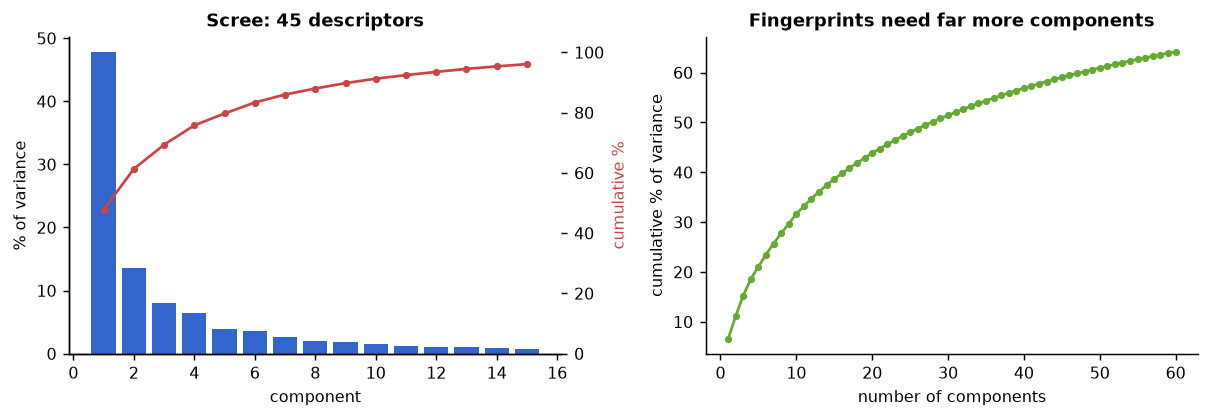

In [13]:
# Scree plot and cumulative variance for the descriptor matrix and for the fingerprints.
pca_fp = PCA(n_components=60, random_state=0).fit(FP)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.3))
axes[0].bar(np.arange(1, 16), pca.explained_variance_ratio_[:15] * 100, color="#36c")
axes[0].set_xlabel("component"); axes[0].set_ylabel("% of variance")
axes[0].set_title("Scree: 45 descriptors")
ax2 = axes[0].twinx()
ax2.plot(np.arange(1, 16), np.cumsum(pca.explained_variance_ratio_[:15]) * 100, "o-", color="#c44", ms=3)
ax2.set_ylabel("cumulative %", color="#c44"); ax2.set_ylim(0, 105)
axes[1].plot(np.arange(1, 61), np.cumsum(pca_fp.explained_variance_ratio_) * 100, "o-", color="#6a3", ms=3)
axes[1].set_xlabel("number of components"); axes[1].set_ylabel("cumulative % of variance")
axes[1].set_title("Fingerprints need far more components")
fig.tight_layout()
n90 = int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), 0.90) + 1)
print("descriptors: PC1 %.1f%%, PC1+PC2 %.1f%%, components for 90%% of variance: %d of 45"
      % (100 * pca.explained_variance_ratio_[0], 100 * pca.explained_variance_ratio_[:2].sum(), n90))
print("fingerprints: PC1 %.1f%%, first 60 components %.1f%% of variance"
      % (100 * pca_fp.explained_variance_ratio_[0], 100 * pca_fp.explained_variance_ratio_.sum()))

<p class="caption"><b>Figure 5.</b> Left: the scree plot of the 45 descriptors — the first component alone carries about 48% of the variance (it is essentially "molecular size", as the loadings below confirm), the first two about 61%, and ten components reach 90%. Right: the same cumulative curve for the 2,048 fingerprint bits, where the first component carries only about 6.5% and sixty components barely exceed 60%. Sparse binary data have no dominant directions, which is why PCA is a poor compressor for fingerprints and why the chemical-space maps in Section 5 are built from a non-linear embedding instead. The practical rule: if the first two components explain less than about 30% of the variance, a two-dimensional PCA scatter plot is a shadow, not a summary<sup class="c"><a href="#r11">[11]</a></sup><sup class="c"><a href="#r16">[16]</a></sup>.</p>

correlation of PC1 with molecular weight: 0.979 | with pActivity: 0.078
correlation of PC2 with FractionCSP3: 0.857 | with NumAromaticRings: -0.306


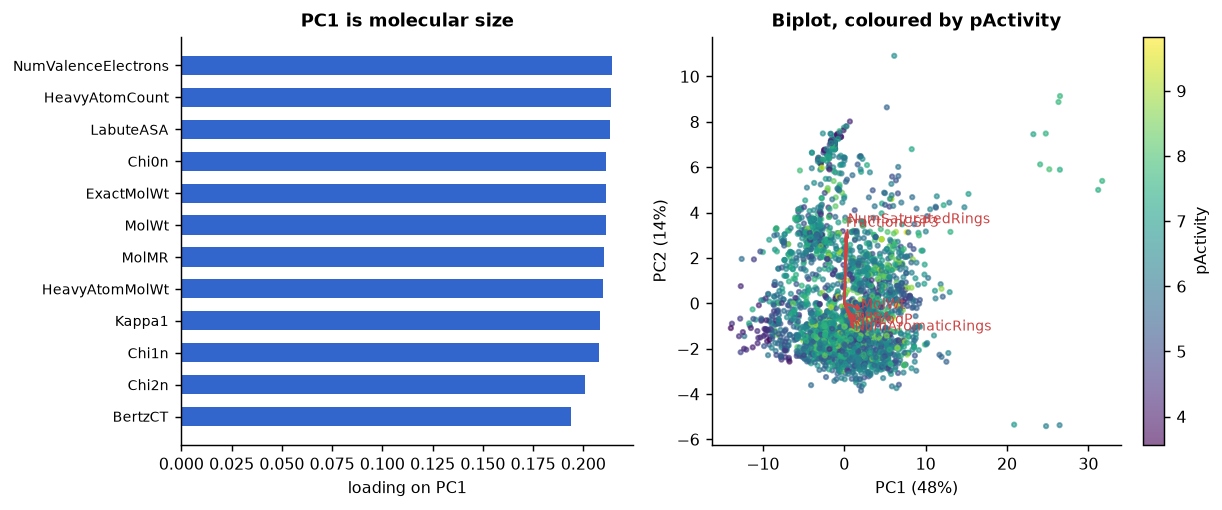

In [14]:
# Loadings and a biplot: what the first two components of the descriptor space mean.
load = pd.DataFrame(pca.components_[:2].T, index=DESC_NAMES, columns=["PC1", "PC2"])
scores = pca.transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.0))
topload = load.reindex(load["PC1"].abs().sort_values(ascending=False).index).head(12).iloc[::-1]
axes[0].barh(np.arange(len(topload)), topload["PC1"], color="#36c", height=0.6)
axes[0].set_yticks(np.arange(len(topload))); axes[0].set_yticklabels(topload.index, fontsize=7.5)
axes[0].set_xlabel("loading on PC1"); axes[0].set_title("PC1 is molecular size")
sc = axes[1].scatter(scores[:, 0], scores[:, 1], c=y, s=6, cmap="viridis", alpha=0.6)
for name in ["MolWt", "MolLogP", "TPSA", "FractionCSP3", "NumSaturatedRings", "NumAromaticRings"]:
    v = load.loc[name] * 9
    axes[1].arrow(0, 0, v["PC1"], v["PC2"], color="#c44", width=0.02, head_width=0.25, length_includes_head=True)
    axes[1].text(v["PC1"] * 1.08, v["PC2"] * 1.08, name, color="#c44", fontsize=7.5)
axes[1].set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.0f}%)")
axes[1].set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.0f}%)")
axes[1].set_title("Biplot, coloured by pActivity")
fig.colorbar(sc, ax=axes[1], fraction=0.046, label="pActivity")
fig.tight_layout()
print("correlation of PC1 with molecular weight: %.3f | with pActivity: %.3f"
      % (np.corrcoef(scores[:, 0], d['MolWt'])[0, 1], np.corrcoef(scores[:, 0], y)[0, 1]))
print("correlation of PC2 with FractionCSP3: %.3f | with NumAromaticRings: %.3f"
      % (np.corrcoef(scores[:, 1], d['FractionCSP3'])[0, 1], np.corrcoef(scores[:, 1], d['NumAromaticRings'])[0, 1]))

<p class="caption"><b>Figure 6.</b> Left: the twelve largest loadings on PC1 — molecular weight, heavy-atom count, valence electrons, Labute surface area, the Chi and Kappa indices — all pointing the same way, which identifies PC1 as a size axis (its correlation with molecular weight is printed below the figure and exceeds 0.9 in absolute value). Right: the biplot, with compounds as points coloured by potency and six descriptors as arrows. An arrow's direction shows how that descriptor increases across the plane and its length how much of it the plane captures. PC2 is dominated by saturation — the fraction of sp3 carbons, the counts of saturated and aliphatic rings all load on it near +0.35 — so the vertical axis separates flat aromatic molecules from three-dimensional saturated ones, while aromatic ring count pulls the other way. The weak colour gradient is the honest message: potency is <em>not</em> a function of the first two principal components of bulk properties (PC1 correlates with pActivity at only about 0.08), which is exactly why fingerprint models beat descriptor models in Unit 11.</p>

In [15]:
# Reconstruction: how much of the data survives a k-component compression?
rows = []
for k in [1, 2, 3, 5, 10, 20, 45]:
    pk = PCA(n_components=k, random_state=0).fit(Z)
    rec = pk.inverse_transform(pk.transform(Z))
    rows.append({"components": k, "variance_explained": pk.explained_variance_ratio_.sum(),
                 "reconstruction_RMSE": float(np.sqrt(((Z - rec) ** 2).mean())),
                 "ridge_R2_on_scores": cross_val_score(Ridge(alpha=10.0), pk.transform(Z), y, cv=cv5, scoring="r2").mean()})
pd.DataFrame(rows).set_index("components").round(3)

,variance_explained,reconstruction_RMSE,ridge_R2_on_scores
components,,,
1,0.478,0.723,-0.001
2,0.613,0.622,-0.002
3,0.694,0.554,-0.001
5,0.797,0.450,0.072
10,0.913,0.296,0.116
20,0.984,0.127,0.162
45,1.000,0.000,0.194


<p class="caption"><b>Table (Section 4.2).</b> PCA as a lossy compression of the standardised descriptor matrix. Ten components retain 91% of the variance and reconstruct the 45 columns with a root-mean-square error of about 0.30 standard-deviation units; twenty retain 98% and reconstruct to 0.13. The last column is the one that matters for modelling, and it carries the warning: a ridge regression on the first ten components reaches R² ≈ 0.12 and on twenty about 0.16, against 0.19 on all 45 — so a compression that keeps 91% of the <em>variance</em> throws away a third of the <em>predictive information</em>. Variance is not relevance: PCA is unsupervised and has no reason to put the target-related directions first. Use it to compress, to visualise and to decorrelate, not as a free accuracy gain — and, being a fitted transformation, always inside the cross-validation.</p>

## 5. Non-linear embeddings: t-SNE and UMAP

PCA is a rotation: it preserves global structure and large distances, and it cannot unfold a curved manifold. Classical multidimensional scaling, which places points so that their map distances match a given distance matrix<sup class="c"><a href="#r17">[17]</a></sup>, has the same linear limitation when the distances are Euclidean. Two neighbour-embedding methods dominate practice instead.

- **t-SNE** converts distances into neighbour probabilities and finds a two-dimensional arrangement whose neighbour probabilities match, with a heavy-tailed kernel in the map that spreads moderately distant points apart. Its one essential hyperparameter, **perplexity**, is the effective number of neighbours each point attends to. It preserves local neighbourhoods and *destroys* global geometry: distances between clusters in a t-SNE map carry little information<sup class="c"><a href="#r18">[18]</a></sup><sup class="c"><a href="#r23">[23]</a></sup>.
- **UMAP** builds a fuzzy nearest-neighbour graph and optimises a low-dimensional layout of it<sup class="c"><a href="#r19">[19]</a></sup>. It is faster, retains somewhat more global structure, and can transform new points — but it has the same fundamental character: a neighbourhood-preserving projection whose large-scale features must not be over-read<sup class="c"><a href="#r20">[20]</a></sup><sup class="c"><a href="#r21">[21]</a></sup>.

Both are run here on the first 60 principal components of the fingerprint matrix, which is the standard recipe: reduce linearly to kill the noise and the cost, then embed.

/usr/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
embedded 2764 compounds from 60 fingerprint PCs
the five largest scaffold families cover 380 compounds (14%)


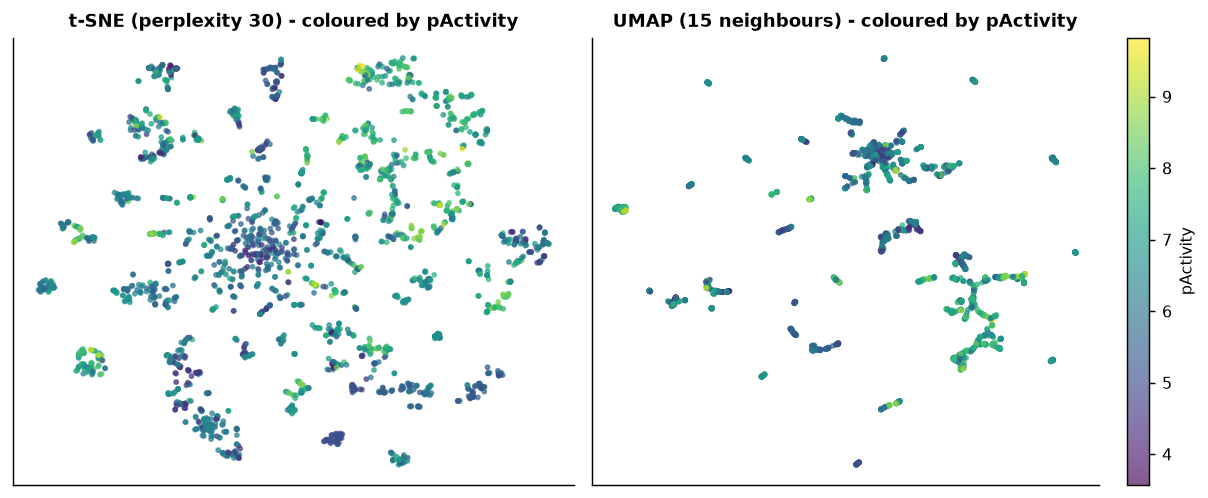

In [16]:
# Chemical space of the 2,764 ROCK1 compounds: t-SNE and UMAP on 60 fingerprint PCs. (~40 s)
from sklearn.manifold import TSNE
emb_in = pca_fp.transform(FP)
tsne_xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=0, max_iter=500).fit_transform(emb_in)
umap_xy = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(emb_in) if HAVE_UMAP else None
big = pd.Series(scaffold).value_counts().head(5).index
fam = np.array([list(big).index(s) if s in set(big) else -1 for s in scaffold])
panels = [("t-SNE (perplexity 30)", tsne_xy)] + ([("UMAP (15 neighbours)", umap_xy)] if HAVE_UMAP else [])
fig, axes = plt.subplots(1, len(panels), figsize=(9.4 if len(panels) == 2 else 5.2, 3.9), squeeze=False)
for ax, (name, xy) in zip(axes[0], panels):
    s0 = ax.scatter(xy[:, 0], xy[:, 1], c=y, s=5, cmap="viridis", alpha=0.65)
    ax.set_title(name + " - coloured by pActivity"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(s0, ax=axes[0][-1], fraction=0.046, label="pActivity")
fig.tight_layout()
print("embedded %d compounds from %d fingerprint PCs" % (emb_in.shape[0], emb_in.shape[1]))
print("the five largest scaffold families cover %d compounds (%.0f%%)" % (int((fam >= 0).sum()), 100 * (fam >= 0).mean()))

<p class="caption"><b>Figure 7.</b> The chemical space of the dataset as seen by two neighbour embeddings, coloured by potency. Both maps show many small islands rather than a continuum — the signature of a dataset built from discrete series — and both show potency varying <em>within</em> islands as well as between them, which is the geometric statement of the activity-cliff problem. The two layouts are not comparable point by point: only the neighbourhood structure is meaningful, and the position, size and separation of the islands differ between the methods and between runs with different seeds.</p>

t-SNE (perplexity 30) : of the 10 nearest neighbours in the map, 29.5% share the compound's scaffold
UMAP (15 neighbours)  : of the 10 nearest neighbours in the map, 27.6% share the compound's scaffold


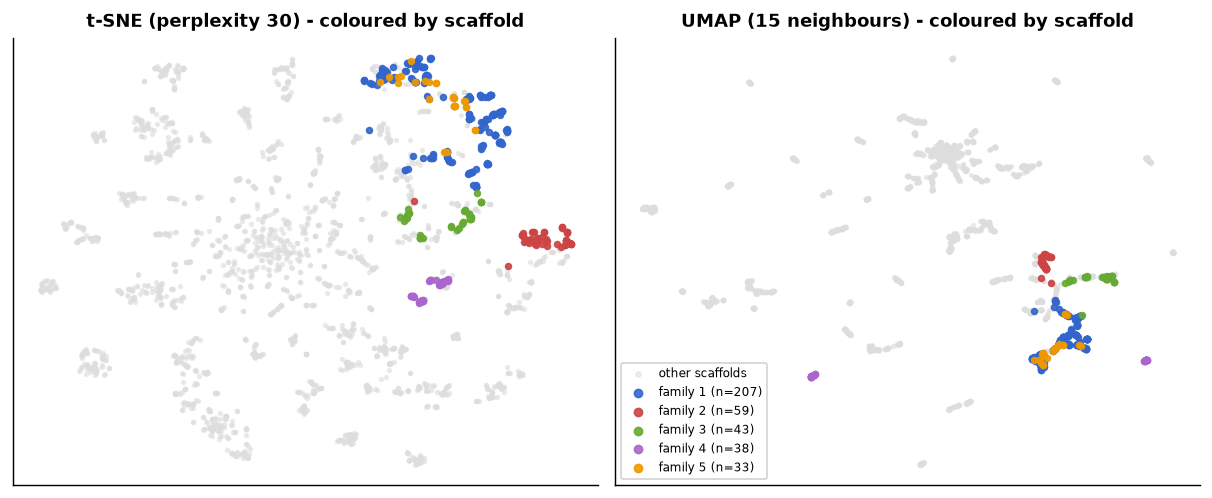

In [17]:
# The same embedding coloured by Bemis-Murcko scaffold family: do the islands correspond to chemical series?
fig, axes = plt.subplots(1, len(panels), figsize=(9.4 if len(panels) == 2 else 5.2, 3.9), squeeze=False)
cols = np.array(["#dddddd", "#36c", "#c44", "#6a3", "#a6c", "#e90"])
for ax, (name, xy) in zip(axes[0], panels):
    ax.scatter(xy[fam < 0, 0], xy[fam < 0, 1], c=cols[0], s=4, alpha=0.5, label="other scaffolds")
    for f in range(5):
        m = fam == f
        ax.scatter(xy[m, 0], xy[m, 1], c=cols[f + 1], s=10, alpha=0.9, label=f"family {f+1} (n={int(m.sum())})")
    ax.set_title(name + " - coloured by scaffold"); ax.set_xticks([]); ax.set_yticks([])
axes[0][-1].legend(fontsize=6.5, markerscale=1.4, loc="best")
fig.tight_layout()
from scipy.spatial import cKDTree
for name, xy in panels:
    tree = cKDTree(xy)
    nb = tree.query(xy, k=11)[1][:, 1:]
    same = np.mean([(scaffold[nb[i]] == scaffold[i]).mean() for i in range(len(xy))])
    print("%-22s: of the 10 nearest neighbours in the map, %.1f%% share the compound's scaffold" % (name, 100 * same))

<p class="caption"><b>Figure 8.</b> The same two maps coloured by the five largest Bemis–Murcko scaffold families. The families<sup class="c"><a href="#r34">[34]</a></sup> occupy coherent territories, confirming that the islands are chemical series rather than artefacts — and the printed diagnostic quantifies it: about 28–30% of each compound's ten nearest neighbours in the map share its exact scaffold, which is far above the chance level given 1,218 scaffolds. This is the clearest picture of why the scaffold split of Unit 12 is hard: a random split samples points from inside every island, while a scaffold split removes whole islands.</p>

### 5.1 False clusters: the failure mode of neighbour embeddings

A neighbour embedding always produces a picture with structure, because the optimisation's job is to spread points apart. Give it data with no clusters at all and it will still draw some<sup class="c"><a href="#r22">[22]</a></sup><sup class="c"><a href="#r23">[23]</a></sup>. The experiment: 600 points of pure 30-dimensional Gaussian noise — one homogeneous blob by construction — embedded at three perplexities, with the apparent clustering quantified by the silhouette score of a six-cluster k-means fit in the map and in the original space.

perplexity   5 -> silhouette of 6 k-means clusters: 0.350 in the map, 0.025 in the original 30-D data
perplexity  30 -> silhouette of 6 k-means clusters: 0.339 in the map, 0.025 in the original 30-D data
perplexity 100 -> silhouette of 6 k-means clusters: 0.338 in the map, 0.025 in the original 30-D data


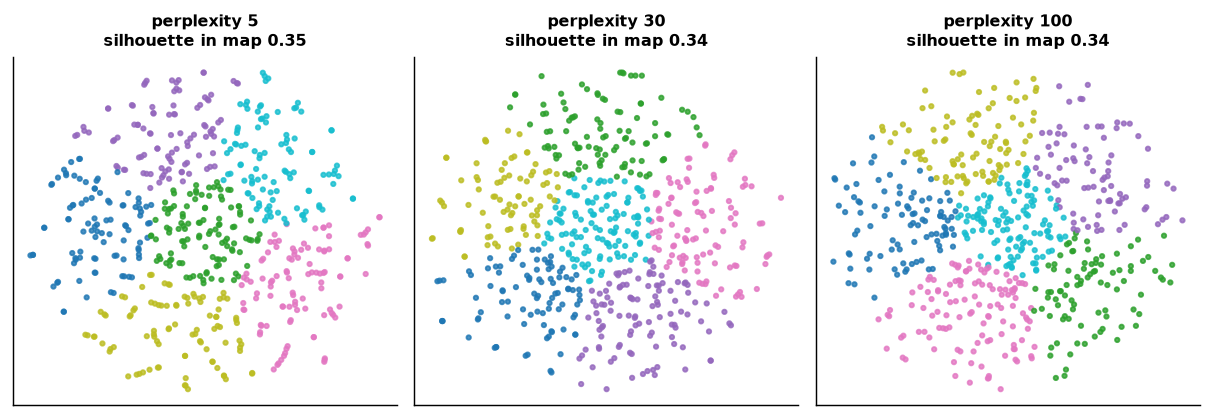

In [18]:
# t-SNE on structureless data: the clusters you see are made by the method. (~15 s)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
rs = np.random.RandomState(0)
noise = rs.normal(size=(600, 30))
sil_orig = silhouette_score(noise, KMeans(6, n_init=5, random_state=0).fit_predict(noise))
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.3))
for ax, perp in zip(axes, [5, 30, 100]):
    xy = TSNE(n_components=2, perplexity=perp, init="pca", random_state=0, max_iter=400).fit_transform(noise)
    lab = KMeans(6, n_init=5, random_state=0).fit_predict(xy)
    s_map = silhouette_score(xy, lab)
    ax.scatter(xy[:, 0], xy[:, 1], c=lab, s=6, cmap="tab10", alpha=0.8)
    ax.set_title(f"perplexity {perp}\nsilhouette in map {s_map:.2f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
    print("perplexity %3d -> silhouette of 6 k-means clusters: %.3f in the map, %.3f in the original 30-D data"
          % (perp, s_map, sil_orig))
fig.tight_layout()

<p class="caption"><b>Figure 9.</b> Six hundred points of pure Gaussian noise, embedded by t-SNE at three perplexities and coloured by a six-cluster k-means fit <em>of the map</em>. All three panels look like data with structure; the silhouette score of those clusters is about 0.34–0.35 in the map against about 0.03 in the original 30-dimensional space, where there is nothing. Low perplexity fragments the blob into more and tighter islands, high perplexity into fewer — the number of apparent clusters is a hyperparameter, not a property of the data. The discipline that follows: never cluster in the embedding and report the clusters as findings; cluster in the original space (or on the original distances) and use the embedding only to display the result, and always show at least two perplexities or neighbour settings.</p>

<div class="exercise"><h4>Exercise 2</h4>
<p>Re-run Figure 7 with <code>perplexity=5</code> and <code>perplexity=150</code> and with UMAP at <code>n_neighbors=5</code> and <code>n_neighbors=100</code>. Which conclusions about the chemical space survive all four pictures? Write down the one sentence about the dataset that you would be willing to defend from these maps.</p></div>

## 6. The curse of dimensionality

In high dimension, volume grows so fast that every point is far from every other and — more damagingly — *all pairwise distances become similar*. Since nearest-neighbour methods, kernels, clustering and any similarity-based applicability domain depend on the *contrast* between near and far, their foundation dissolves as p grows<sup class="c"><a href="#r24">[24]</a></sup><sup class="c"><a href="#r25">[25]</a></sup>. The simulation below measures it directly: 500 uniform random points in d dimensions, and the relative contrast (max − min)/min of their pairwise distances, plus the coefficient of variation of those distances.

         min    mean     max  relative_contrast     cv
d                                                     
2      0.005   1.752   6.251           1350.640  0.520
5      0.315   2.935   8.193             25.048  0.322
10     1.058   4.327   8.258              6.802  0.220
20     2.627   6.200  10.533              3.009  0.157
50     5.879   9.950  14.578              1.480  0.102
100    9.780  14.087  19.306              0.974  0.071
500   27.246  31.596  35.885              0.317  0.032
2000  58.782  63.216  67.441              0.147  0.015


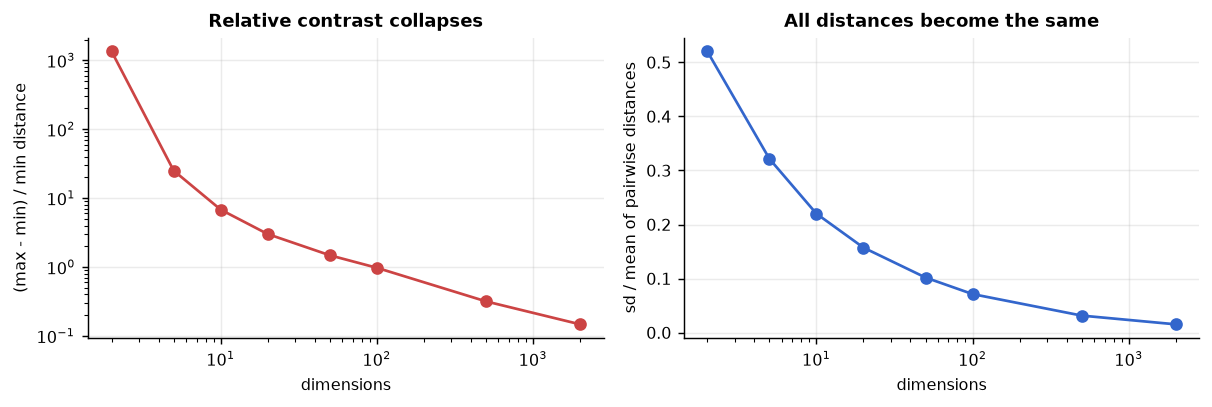

In [19]:
# Distance concentration: the same 500 points, more and more dimensions.
from scipy.spatial.distance import pdist
rs = np.random.RandomState(0)
rows = []
for dim in [2, 5, 10, 20, 50, 100, 500, 2000]:
    P = rs.normal(size=(500, dim))
    dd = pdist(P)
    rows.append({"d": dim, "min": dd.min(), "mean": dd.mean(), "max": dd.max(),
                 "relative_contrast": (dd.max() - dd.min()) / dd.min(), "cv": dd.std() / dd.mean()})
conc = pd.DataFrame(rows).set_index("d")
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.2))
axes[0].loglog(conc.index, conc["relative_contrast"], "o-", color="#c44")
axes[0].set_xlabel("dimensions"); axes[0].set_ylabel("(max - min) / min distance")
axes[0].set_title("Relative contrast collapses")
axes[1].semilogx(conc.index, conc["cv"], "o-", color="#36c")
axes[1].set_xlabel("dimensions"); axes[1].set_ylabel("sd / mean of pairwise distances")
axes[1].set_title("All distances become the same")
for a in axes:
    a.grid(alpha=0.25)
fig.tight_layout()
print(conc.round(3).to_string())

<p class="caption"><b>Figure 10 and table.</b> Distance concentration measured on random Gaussian points. In two dimensions the farthest pair is more than a thousand times further apart than the closest pair and the spread of distances is about half their mean; by 100 dimensions the relative contrast is below 1 and the coefficient of variation is 0.07; by 2,000 dimensions — the size of our fingerprint space — distances vary by about 1.5% around their mean. "Nearest neighbour" stops being a meaningful notion for isotropic high-dimensional data<sup class="c"><a href="#r24">[24]</a></sup>. Two caveats save practice: real data are not isotropic (they lie near a much lower-dimensional manifold, which is why 60 fingerprint components capture most of the structure), and the Tanimoto metric on sparse binary vectors concentrates far more slowly than Euclidean distance on dense ones — which is precisely why cheminformatics uses it<sup class="c"><a href="#r27">[27]</a></sup>. The general lesson stands: before using a distance in high dimension, check that it still discriminates<sup class="c"><a href="#r26">[26]</a></sup>.</p>

### 6.1 What it costs a real model

The simulation is abstract; the next cell makes it concrete by appending columns of pure noise to the 45 standardised descriptors and re-measuring three models. Nothing is removed and no information is added — only the dimension grows.

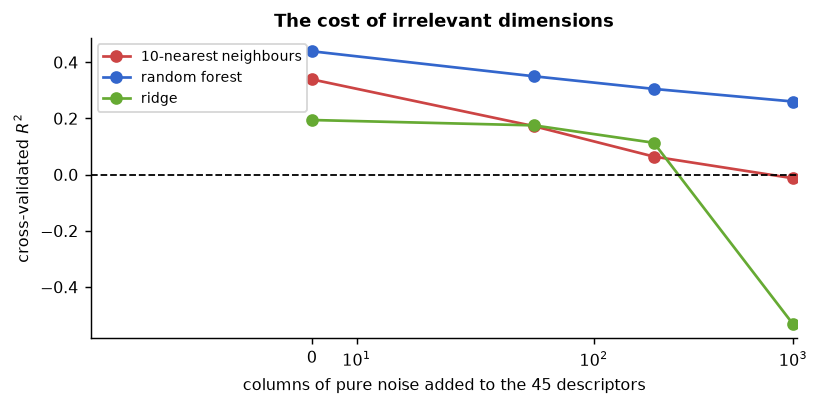

,total_columns,kNN_10_R2,forest_R2,ridge_R2
noise_columns,,,,
0,45,0.339,0.439,0.194
50,95,0.173,0.350,0.175
200,245,0.064,0.305,0.113
1000,1045,-0.013,0.260,-0.533


In [20]:
# Adding pure-noise columns to a real feature matrix: who survives? (~40 s)
from sklearn.neighbors import KNeighborsRegressor
Zd = StandardScaler().fit_transform(D)
rs = np.random.RandomState(0)
rows = []
for extra in [0, 50, 200, 1000]:
    M = np.hstack([Zd, rs.normal(size=(len(y), extra))]) if extra else Zd
    rows.append({"noise_columns": extra, "total_columns": M.shape[1],
                 "kNN_10_R2": cross_val_score(KNeighborsRegressor(10), M, y, cv=cv5, scoring="r2").mean(),
                 "forest_R2": cross_val_score(RandomForestRegressor(n_estimators=60, random_state=0, n_jobs=-1),
                                              M, y, cv=cv5, scoring="r2").mean(),
                 "ridge_R2": cross_val_score(Ridge(alpha=10.0), M, y, cv=cv5, scoring="r2").mean()})
noise_tbl = pd.DataFrame(rows).set_index("noise_columns")
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for col, lab, c in [("kNN_10_R2", "10-nearest neighbours", "#c44"), ("forest_R2", "random forest", "#36c"),
                    ("ridge_R2", "ridge", "#6a3")]:
    ax.plot(noise_tbl.index, noise_tbl[col], "o-", label=lab, color=c)
ax.axhline(0, color="k", ls="--", lw=1)
ax.set_xscale("symlog", linthresh=50)
ax.set_xlabel("columns of pure noise added to the 45 descriptors"); ax.set_ylabel("cross-validated $R^2$")
ax.set_title("The cost of irrelevant dimensions"); ax.legend(fontsize=7.5)
fig.tight_layout()
noise_tbl.round(3)

<p class="caption"><b>Figure 11 and table.</b> The price of dimensions that carry nothing. The nearest-neighbour model, which depends entirely on distance contrast, falls from R² ≈ 0.34 to ≈ 0.17 with 50 noise columns and to ≈ −0.01 with 1,000: its neighbourhoods are now defined by noise. Ridge collapses even harder at 1,000 columns (R² ≈ −0.53) because a fixed penalty cannot control 1,045 coefficients fitted to 2,764 rows — the remedy would be to raise α, i.e. to tune. The random forest degrades gracefully, from ≈ 0.44 to ≈ 0.26, because each split searches for a feature that actually reduces impurity and mostly ignores the rest; this robustness to irrelevant features is one of the reasons tree ensembles are the default for wide scientific tables (Unit 14).</p>

<div class="box key"><h4>Key idea</h4>
<p>Dimensionality is not just a computational cost, it changes the geometry. Added columns that carry no signal make every distance-based method worse, not merely slower — which is the real argument for feature selection, and the reason a model with 45 informative descriptors can beat one with 2,048 mostly empty bits on a small dataset while losing on a large one.</p></div>

<div class="box bridge"><h4>Bridge — where this unit sits</h4>
<p><a href="../U11_Supervised_Workflow/index.html">Unit 11</a> established why every fitted transformation in this unit lives inside the pipeline; <a href="../U12_Validation/index.html">Unit 12</a> supplies the splits under which the hashed-scaffold experiment of Section 2.4 was judged; <a href="../U14_Ensembles_Tuning/index.html">Unit 14</a> takes the 45-descriptor and fingerprint matrices into tuned gradient boosting; <a href="../U15_Clustering/index.html">Unit 15</a> clusters the same chemical space properly, in the original metric rather than in the embedding; <a href="../U16_Interpretability/index.html">Unit 16</a> replaces the importance bar charts of Section 3.1 with SHAP values; <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> turns distance-to-training into a calibrated applicability domain; and <a href="../U21_Omics/index.html">Unit 21</a> treats the expression matrix of Section 3.2 as a biological question rather than a feature-selection exercise. The chemistry of the two molecular representations is <a href="../../../Cheminformatics/U5_Descriptors_Fingerprints/index.html">Unit 5 of the cheminformatics course</a> and the chemical-space mapping <a href="../../../Cheminformatics/U8_Chemical_Space/index.html">its Unit 8</a>; the linear-algebra background to the SVD and the machine-learning treatment of dimensionality reduction are in the artificial-intelligence course <a href="../../../BGM411/Python/index.html">BGM411</a>.</p></div>

## 7. Summary

You should now be able to explain, without notes:

- why a feature matrix is a scientific claim, and how descriptors, fingerprints and expression matrices differ in rows per column, sparsity and correlation;
- how to construct domain features (ratios, densities, transformations, hashed categoricals) and why they often add less than a bigger descriptor panel;
- that identity-like features (scaffold, patient, batch) inflate random-split scores and collapse under a group split;
- the three families of selection, the rule that selection is refitted inside every fold, and the fact that selection usually costs a regularised model accuracy while buying interpretability and cost;
- how to measure selection stability with the Jaccard index, and why a 20-gene signature from 138 samples is a hypothesis rather than a result;
- PCA as the SVD of the centred matrix, including what the scree plot, loadings, biplot and reconstruction error each tell you, and why variance explained is not predictive information;
- what t-SNE and UMAP preserve, and how to recognise a false cluster;
- distance concentration and its consequences for neighbours, kernels and applicability domains.

The numbers to remember: the hashed-scaffold feature is worth +0.08 R² under a random split and −0.05 under a scaffold split; selection stability is Jaccard ≈ 0.78 for 45 descriptors on 2,764 compounds and ≈ 0.33 for 500 genes on 138 samples, with only 3 of 20 genes selected in every fold; ten principal components keep 91% of descriptor variance but only two thirds of its predictive value; and t-SNE assigns a silhouette of about 0.34 to clusters that do not exist.

## 8. Self-assessment

<details><summary>1. Your model improves when you add a one-hot encoding of the assay identifier. Should you keep it?</summary>Only if the assay will be known for future predictions and you validate under a split that groups by assay. Otherwise it is an identity feature of the same kind as the hashed scaffold: +0.08 R² under a random split, −0.05 under a group split.</details>

<details><summary>2. Why does feature selection not improve the ridge model on the 45 descriptors?</summary>Because L2 regularisation already shrinks redundant and useless columns; removing them removes some information and adds a selection step that can only be estimated with error. Selection buys interpretability, measurement cost and stability, not accuracy, when the model is already regularised.</details>

<details><summary>3. A collaborator selects the 50 most differentially expressed genes on the whole dataset, then cross-validates a classifier on those 50. What is wrong and how large is the effect?</summary>The selection saw the test labels, so the cross-validation is not blind; Unit 11 measured the same mistake on fingerprints (R² 0.15 against −0.34 at n = 150, and 0.46 against −0.24 on pure noise). On p ≫ n expression data the effect is at its largest.</details>

<details><summary>4. What does a Jaccard index of 0.33 across folds mean for a published signature?</summary>That two folds of the same dataset agree on only a third of the selected features. The signature is one of many equivalent subsets; report selection frequencies or use stability selection, and do not present the specific gene list as the discovery.</details>

<details><summary>5. PC1 explains 48% of the variance of your descriptor matrix. Is it the most predictive direction?</summary>Not necessarily — PCA is unsupervised. Here PC1 is molecular size and correlates with pActivity at about 0.08; ten components keep 91% of the variance but drop the ridge R² from 0.19 to 0.12. Variance explained measures reconstruction, not relevance.</details>

<details><summary>6. Why standardise before PCA, and when should you not?</summary>Standardise when columns have different units or wildly different scales, otherwise the largest-variance column dominates the first component by accident. Do not standardise when all columns are already in the same meaningful unit (fingerprint bits, log-expression values), where relative variance is itself information.</details>

<details><summary>7. Two clusters in your t-SNE map are far apart. What can you conclude?</summary>Almost nothing about how different they are. t-SNE preserves neighbourhoods, not distances between groups; the gap can be an artefact of perplexity or initialisation. Verify structure in the original space, and show more than one hyperparameter setting.</details>

<details><summary>8. Why does PCA need sixty components on fingerprints and ten on descriptors?</summary>Because the descriptor columns are strongly correlated measures of a few underlying properties (mostly size), while fingerprint bits are sparse, nearly uncorrelated records of distinct substructures — there is no dominant direction to find, so variance is spread across hundreds of components.</details>

<details><summary>9. How does distance concentration affect an applicability domain built on Euclidean distance over 2,048 bits?</summary>It makes it nearly useless: in 2,000 isotropic dimensions all distances fall within a couple of percent of their mean, so no threshold separates "inside" from "outside". Use Tanimoto similarity on the sparse binary vectors, or a distance in a reduced space, and check that the chosen metric still discriminates.</details>

<details><summary>10. When is feature hashing preferable to one-hot encoding?</summary>When the number of levels is large, unbounded or unknown in advance (scaffolds, assay identifiers, text tokens). It gives a fixed width and handles unseen levels at the price of collisions — here 1,218 scaffolds compressed into 256 buckets, 13 of them sharing the most crowded bucket.</details>

<details><summary>11. You must deliver a diagnostic panel of at most 10 genes. Which selection procedure do you use?</summary>A stability-based one: repeat the selection over many resamples and keep the genes chosen most often, then report cross-validated performance of the fixed 10-gene panel with selection still performed inside the folds for the estimate. Expect a modest performance loss against the full matrix and a large gain in deliverability.</details>

<details><summary>12. Permutation importance gives two correlated descriptors near-zero importance each. What does that mean?</summary>That either one can replace the other: shuffling one leaves the signal intact through its partner, so neither looks necessary. It is a statement about redundancy, not irrelevance — group the correlated block and permute it jointly, or use a method designed for correlated features.</details>

## Glossary

<dl class="gloss">
<dt>Biplot</dt><dd>A scatter plot of PCA scores with the feature loadings drawn as arrows in the same plane.</dd>
<dt>Curse of dimensionality</dt><dd>The loss of distance contrast and the explosion of required sample size as the number of features grows.</dd>
<dt>Embedded selection</dt><dd>Selection performed as part of model fitting, as by the L1 penalty of the lasso.</dd>
<dt>Feature hashing</dt><dd>Mapping categorical levels into a fixed number of buckets with a hash function, accepting collisions.</dd>
<dt>Filter selection</dt><dd>Model-independent ranking of features by a univariate score (variance, correlation, F statistic, mutual information).</dd>
<dt>Jaccard index</dt><dd>Size of the intersection over size of the union of two sets; used here to measure selection stability across folds.</dd>
<dt>Loading</dt><dd>The weight of an original feature in a principal component; the entries of the matrix V of the SVD.</dd>
<dt>Mutual information</dt><dd>An information-theoretic measure of dependence that detects non-linear as well as linear relationships.</dd>
<dt>Perplexity</dt><dd>t-SNE's hyperparameter setting the effective number of neighbours each point considers.</dd>
<dt>Permutation importance</dt><dd>The loss in held-out performance when one feature's values are shuffled.</dd>
<dt>p ≫ n</dt><dd>The regime with more features than samples, where models fit perfectly in sample and selections are unstable.</dd>
<dt>PCA</dt><dd>Projection onto the orthogonal directions of maximal variance; computed as the SVD of the centred data matrix.</dd>
<dt>Reconstruction error</dt><dd>The distance between the original data and their projection back from a truncated set of components.</dd>
<dt>RFE</dt><dd>Recursive feature elimination: fit, rank, drop the weakest features, repeat.</dd>
<dt>Scree plot</dt><dd>Variance explained against component number; used to choose how many components to keep.</dd>
<dt>Stability selection</dt><dd>Repeating a selection over resamples and keeping features chosen with high frequency.</dd>
<dt>t-SNE / UMAP</dt><dd>Neighbour-embedding methods that preserve local structure for visualisation and distort global geometry.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Guyon I, Elisseeff A. An introduction to feature extraction. In: <em>Feature Extraction: Foundations and Applications</em>. Studies in Fuzziness and Soft Computing, vol 207. Springer; 2006:1-25. <a href="https://doi.org/10.1007/978-3-540-35488-8_1">doi:10.1007/978-3-540-35488-8_1</a></li>
<li id="r2">Saeys Y, Inza I, Larrañaga P. A review of feature selection techniques in bioinformatics. <em>Bioinformatics</em>. 2007;23(19):2507-2517. <a href="https://doi.org/10.1093/bioinformatics/btm344">doi:10.1093/bioinformatics/btm344</a></li>
<li id="r3">Ambroise C, McLachlan GJ. Selection bias in gene extraction on the basis of microarray gene-expression data. <em>Proc Natl Acad Sci USA</em>. 2002;99(10):6562-6566. <a href="https://doi.org/10.1073/pnas.102102699">doi:10.1073/pnas.102102699</a></li>
<li id="r4">Meinshausen N, Bühlmann P. Stability selection. <em>J R Stat Soc Series B</em>. 2010;72(4):417-473. <a href="https://doi.org/10.1111/j.1467-9868.2010.00740.x">doi:10.1111/j.1467-9868.2010.00740.x</a></li>
<li id="r5">Kalousis A, Prados J, Hilario M. Stability of feature selection algorithms: a study on high-dimensional spaces. <em>Knowl Inf Syst</em>. 2007;12:95-116. <a href="https://doi.org/10.1007/s10115-006-0040-8">doi:10.1007/s10115-006-0040-8</a></li>
<li id="r6">Guyon I, Weston J, Barnhill S, Vapnik V. Gene selection for cancer classification using support vector machines. <em>Mach Learn</em>. 2002;46:389-422. <a href="https://doi.org/10.1023/A:1012487302797">doi:10.1023/A:1012487302797</a></li>
<li id="r7">Tibshirani R. Regression shrinkage and selection via the lasso. <em>J R Stat Soc Series B</em>. 1996;58(1):267-288. <a href="https://doi.org/10.1111/j.2517-6161.1996.tb02080.x">doi:10.1111/j.2517-6161.1996.tb02080.x</a></li>
<li id="r8">Zou H, Hastie T. Regularization and variable selection via the elastic net. <em>J R Stat Soc Series B</em>. 2005;67(2):301-320. <a href="https://doi.org/10.1111/j.1467-9868.2005.00503.x">doi:10.1111/j.1467-9868.2005.00503.x</a></li>
<li id="r9">Altmann A, Toloşi L, Sander O, Lengauer T. Permutation importance: a corrected feature importance measure. <em>Bioinformatics</em>. 2010;26(10):1340-1347. <a href="https://doi.org/10.1093/bioinformatics/btq134">doi:10.1093/bioinformatics/btq134</a></li>
<li id="r10">Strobl C, Boulesteix AL, Zeileis A, Hothorn T. Bias in random forest variable importance measures: illustrations, sources and a solution. <em>BMC Bioinformatics</em>. 2007;8:25. <a href="https://doi.org/10.1186/1471-2105-8-25">doi:10.1186/1471-2105-8-25</a></li>
<li id="r11">Jolliffe IT, Cadima J. Principal component analysis: a review and recent developments. <em>Philos Trans R Soc A</em>. 2016;374:20150202. <a href="https://doi.org/10.1098/rsta.2015.0202">doi:10.1098/rsta.2015.0202</a></li>
<li id="r12">Pearson K. On lines and planes of closest fit to systems of points in space. <em>Philos Mag</em>. 1901;2(11):559-572. <a href="https://doi.org/10.1080/14786440109462720">doi:10.1080/14786440109462720</a></li>
<li id="r13">Hotelling H. Analysis of a complex of statistical variables into principal components. <em>J Educ Psychol</em>. 1933;24(6):417-441. <a href="https://doi.org/10.1037/h0071325">doi:10.1037/h0071325</a></li>
<li id="r14">Eckart C, Young G. The approximation of one matrix by another of lower rank. <em>Psychometrika</em>. 1936;1:211-218. <a href="https://doi.org/10.1007/BF02288367">doi:10.1007/BF02288367</a></li>
<li id="r15">Halko N, Martinsson PG, Tropp JA. Finding structure with randomness: probabilistic algorithms for constructing approximate matrix decompositions. <em>SIAM Rev</em>. 2011;53(2):217-288. <a href="https://doi.org/10.1137/090771806">doi:10.1137/090771806</a></li>
<li id="r16">Lever J, Krzywinski M, Altman N. Principal component analysis. <em>Nat Methods</em>. 2017;14:641-642. <a href="https://doi.org/10.1038/nmeth.4346">doi:10.1038/nmeth.4346</a></li>
<li id="r17">Kruskal JB. Multidimensional scaling by optimizing goodness of fit to a nonmetric hypothesis. <em>Psychometrika</em>. 1964;29:1-27. <a href="https://doi.org/10.1007/BF02289565">doi:10.1007/BF02289565</a></li>
<li id="r18">van der Maaten L, Hinton G. Visualizing data using t-SNE. <em>J Mach Learn Res</em>. 2008;9:2579-2605. <a href="https://www.jmlr.org/papers/v9/vandermaaten08a.html">jmlr.org/papers/v9/vandermaaten08a.html</a> (JMLR assigns no DOI)</li>
<li id="r19">McInnes L, Healy J, Melville J. UMAP: uniform manifold approximation and projection for dimension reduction. <em>arXiv</em>. 2018. <a href="https://doi.org/10.48550/arXiv.1802.03426">doi:10.48550/arXiv.1802.03426</a></li>
<li id="r20">Kobak D, Berens P. The art of using t-SNE for single-cell transcriptomics. <em>Nat Commun</em>. 2019;10:5416. <a href="https://doi.org/10.1038/s41467-019-13056-x">doi:10.1038/s41467-019-13056-x</a></li>
<li id="r21">Becht E, McInnes L, Healy J, et al. Dimensionality reduction for visualizing single-cell data using UMAP. <em>Nat Biotechnol</em>. 2019;37:38-44. <a href="https://doi.org/10.1038/nbt.4314">doi:10.1038/nbt.4314</a></li>
<li id="r22">Chari T, Pachter L. The specious art of single-cell genomics. <em>PLoS Comput Biol</em>. 2023;19(8):e1011288. <a href="https://doi.org/10.1371/journal.pcbi.1011288">doi:10.1371/journal.pcbi.1011288</a></li>
<li id="r23">Wattenberg M, Viégas F, Johnson I. How to use t-SNE effectively. <em>Distill</em>. 2016;1(10):e2. <a href="https://doi.org/10.23915/distill.00002">doi:10.23915/distill.00002</a></li>
<li id="r24">Beyer K, Goldstein J, Ramakrishnan R, Shaft U. When is "nearest neighbor" meaningful? In: <em>ICDT 1999</em>. LNCS 1540. Springer; 1999:217-235. <a href="https://doi.org/10.1007/3-540-49257-7_15">doi:10.1007/3-540-49257-7_15</a></li>
<li id="r25">Aggarwal CC, Hinneburg A, Keim DA. On the surprising behavior of distance metrics in high dimensional space. In: <em>ICDT 2001</em>. LNCS 1973. Springer; 2001:420-434. <a href="https://doi.org/10.1007/3-540-44503-X_27">doi:10.1007/3-540-44503-X_27</a></li>
<li id="r26">Domingos P. A few useful things to know about machine learning. <em>Commun ACM</em>. 2012;55(10):78-87. <a href="https://doi.org/10.1145/2347736.2347755">doi:10.1145/2347736.2347755</a></li>
<li id="r27">Rogers D, Hahn M. Extended-connectivity fingerprints. <em>J Chem Inf Model</em>. 2010;50(5):742-754. <a href="https://doi.org/10.1021/ci100050t">doi:10.1021/ci100050t</a></li>
<li id="r28">Todeschini R, Consonni V. <em>Molecular Descriptors for Chemoinformatics</em>. 2nd ed. Wiley-VCH; 2009. <a href="https://doi.org/10.1002/9783527628766">doi:10.1002/9783527628766</a></li>
<li id="r29">Weinberger K, Dasgupta A, Langford J, Smola A, Attenberg J. Feature hashing for large scale multitask learning. In: <em>Proc. 26th Int. Conf. on Machine Learning (ICML '09)</em>. ACM; 2009:1113-1120. <a href="https://doi.org/10.1145/1553374.1553516">doi:10.1145/1553374.1553516</a></li>
<li id="r30">Papapanou PN, Behle JH, Kebschull M, et al. Subgingival bacterial colonization profiles correlate with gingival tissue gene expression. <em>BMC Microbiol</em>. 2009;9:221. <a href="https://doi.org/10.1186/1471-2180-9-221">doi:10.1186/1471-2180-9-221</a></li>
<li id="r31">Kebschull M, Demmer RT, Grün B, Guarnieri P, Pavlidis P, Papapanou PN. Gingival tissue transcriptomes identify distinct periodontitis phenotypes. <em>J Dent Res</em>. 2014;93(5):459-468. <a href="https://doi.org/10.1177/0022034514527288">doi:10.1177/0022034514527288</a></li>
<li id="r32">Leek JT, Scharpf RB, Bravo HC, et al. Tackling the widespread and critical impact of batch effects in high-throughput data. <em>Nat Rev Genet</em>. 2010;11:733-739. <a href="https://doi.org/10.1038/nrg2825">doi:10.1038/nrg2825</a></li>
<li id="r33">Box GEP, Cox DR. An analysis of transformations. <em>J R Stat Soc Series B</em>. 1964;26(2):211-243. <a href="https://doi.org/10.1111/j.2517-6161.1964.tb00553.x">doi:10.1111/j.2517-6161.1964.tb00553.x</a></li>
<li id="r34">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887-2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009 (free PDF). — Chapters 3 (shrinkage and selection), 14 (unsupervised learning, PCA) and 18 (p ≫ n).</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023 (free PDF). — Chapters 6 and 12 at an introductory level.</li>
<li>Todeschini R, Consonni V. <em>Molecular Descriptors for Chemoinformatics</em>. Wiley-VCH; 2009. — The reference work on what each descriptor measures.</li>
<li>VanderPlas J. <em>Python Data Science Handbook</em>. 2nd ed. O'Reilly; 2022 (free online). — Practical PCA and manifold learning with scikit-learn.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>scikit-learn user guide: "Feature selection", "Decomposing signals in components" and "Manifold learning": <a href="https://scikit-learn.org/stable/modules/feature_selection.html">scikit-learn.org/stable/modules/feature_selection.html</a>.</li>
<li>UMAP documentation, including "Understanding UMAP" and the parameter guide: <a href="https://umap-learn.readthedocs.io/">umap-learn.readthedocs.io</a>.</li>
<li>TeachOpenCADD talktorial T005 (compound clustering) and T006 (maximum common substructures), which map the same chemical space: <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>Practical Cheminformatics (P. Walters) — posts on descriptors, chemical-space visualisation and the perils of t-SNE: <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
</ul>